# 🎨 Stable Diffusion 本地文生图开发

使用本地模型 `stable-diffusion-v1-5`（diffusers 格式，fp16 半精度权重）在 RTX 4060 上生成图片。

**SD 文生图三步原理**：
1. `text_encoder` + `tokenizer`：把提示词（prompt）编码成向量
2. `unet`：从纯噪声图开始，按步数（steps）逐步去噪，反复受到提示词向量引导
3. `vae`：把去噪后的隐空间结果解码成 512×512 的图片

请选择内核：**transformers (15-transformers-basics)**

In [1]:
# 1. 环境检查：确认 GPU 可用
import torch

print(f'torch: {torch.__version__}')
print(f'CUDA 可用: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'显存: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB')
else:
    print('⚠️ 未检测到 GPU，将用 CPU 生成（非常慢，请先确认内核选择正确）')

torch: 2.5.1+cu121
CUDA 可用: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
显存: 8.0 GB


In [2]:
# 2. 加载本地 Stable Diffusion v1.5 管线（约 10~60 秒，只加载一次，后续 cell 复用）
import torch
from diffusers import StableDiffusionPipeline

MODEL_DIR = r'S:\PythonAILearningCourse\04-ai-painting-sdxl\stable-diffusion-v1-5'

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_DIR,
    dtype=torch.float16,   # 半精度：显存减半、速度更快（fp16 权重约 3.5GB）
    variant='fp16',        # 目录里的权重文件名都带 .fp16 后缀，必须指定
)
pipe.to('cuda')                    # 放到 GPU
pipe.enable_attention_slicing()    # 分片计算注意力，降低显存峰值（8GB 显存更稳）

print('✅ 模型加载完成，显存占用约 3 GB，可以开始生成了')

S:\PythonAILearningCourse\15-transformers-basics\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading pipeline components...: 100%|██████████| 7/7 [00:00<00:00, 14.22it/s]


✅ 模型加载完成，显存占用约 3 GB，可以开始生成了


100%|██████████| 20/20 [00:03<00:00,  5.22it/s]


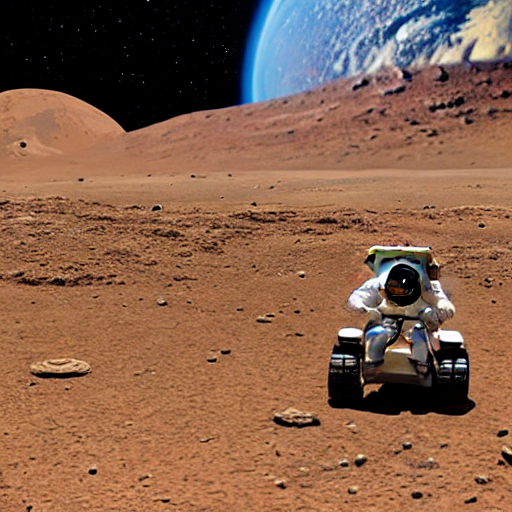

In [3]:
# 3. 文生图：改 prompt 重新运行本 cell 即可（RTX 4060 上 20 步约 4 秒）
# prompt = 'a cute astronaut cat floating in space, stars and nebula background, digital art, highly detailed'
prompt = 'an astronaut riding a horse on Mars'
negative_prompt = 'lowres, bad anatomy, blurry, watermark, text'

image = pipe(
    prompt=prompt,             # 想画什么（英文效果最好）
    negative_prompt=negative_prompt,  # 不想出现什么
    num_inference_steps=20,    # 去噪步数：越大越精细、越慢（常用 20~30）
    guidance_scale=7.5,        # 提示词引导强度：越大越贴合 prompt（常用 6~9）
    height=512, width=512,     # 尺寸必须是 8 的倍数，SD1.5 最佳 512
    generator=torch.manual_seed(42),  # 固定随机种子：同参数生成同一张图，方便对比
).images[0]

# 保存 + 显示
image.save(r'S:\PythonAILearningCourse\04-ai-painting-sdxl\photo\sd_output.png')
image